/var/folders/_6/5sd1d02d7kn3shyrhw5pt9t03r9b0d/T/ipykernel_52785/507201138.py:31: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area = np.trapz(gaussian(t_grid, mu, sigma), t_grid) #integrate the gaussian function over the time grid to get the area under the curve


minimum found at x = [ 0.7108837  29.84687822] f = 0.000619842152857597 after 3 sweeps
The optimal omega0 is: 0.710884 rad/ns which is 0.113141 GHz and the optimal w is: 29.846878 rad/ns which is 4.750278 GHz and the population of the first excited state at the end of the gate time is: 0.999380


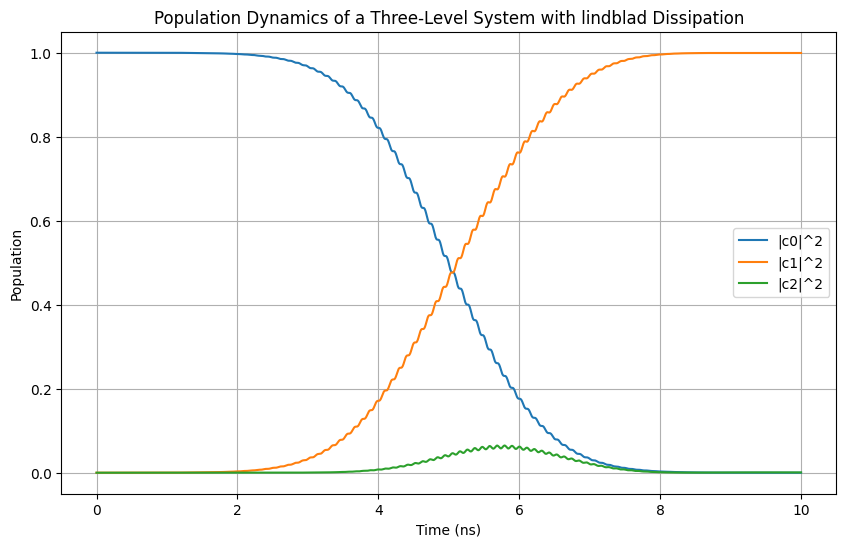

In [2]:
import numpy as np
from scipy.sparse import linalg as sla
import matplotlib.pyplot as plt
from myfunctions import powell_search, gaussian, rk4solve
from part2 import H_number, H_time
from part3 import Lindblad

#create the hamilton and the initial density matrix
##
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz 50x smaller than E_j
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
t1, t2= 200, 150 # the relaxation and dephasing times in ns
gamma= 0.0 * np.array([1/t1,2 * (1/t2 - 1 / (2*t1))]) # the dissipation rates for the two levels
T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
T2 = np.diag([0,1,2]) # adagger a 
T = np.array([T1,T2]) # the array of the two operators
T_g = 10 # gate time in ns
dT_g=0.005 # stepsize
rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]],dtype=complex) # the initial density matrix
mu = T_g/2 # the amplitude is at its maximum at half of the gate time
sigma = T_g/6 # make sure it is close to zero in the start and end

H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0] # the energy gap between the ground state and the first excited state
A= U.T @ np.diag(N) @ U #the coupling term between the different states

t_grid = np.arange(0, T_g + dT_g, dT_g) #grid of time points for the integration from 0 to T_g with step size dT_g
area = np.trapz(gaussian(t_grid, mu, sigma), t_grid) #integrate the gaussian function over the time grid to get the area under the curve
omega0 = np.pi / (abs(A[0, 1]) * area)

###

def cost(omega0,w): # makes a cost function that will tell me how close I am to the target state at the end of the gate time given a certain omega0 and w
    def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
        omega = omega0*gaussian(t,mu,sigma)
        H = H_time(t,H_0,A,omega,w)
        return Lindblad(T, rho, H, gamma)
    t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)
    P1 = C_L[:, 1, 1].real
    cost_value= 1-P1[-1] # the cost function is 1-P1 at the end of the gate time
    return cost_value
x0 = np.array([omega0,w]) # the initial guess for omega0 and w
pset = np.eye(2) # the initial direction vectors are the unit vectors in 2D meaning I will first only change omega0 and then only change w
n= 10 # the number of points to use in the minimum_finder function
N_max = 10 # the maximum number of sweeps to use in the powell_search
tol = 1e-4 # the tolerance for the powell_search
T_p=5 # it will search in the radius T*dx_i
dOmega = 0.1 * omega0 # the step size for omega0
dw = 0.2/ sigma # the step size for w
scale = np.array([dOmega, dw])
x_min, f_min, sweeps = powell_search(cost, x0, pset, N_max, n, T_p, tol, scale=scale)
print(f"The optimal omega0 is: {x_min[0]:.6f} rad/ns which is {x_min[0]/(2*np.pi):.6f} GHz and the optimal w is: {x_min[1]:.6f} rad/ns which is {x_min[1]/(2*np.pi):.6f} GHz and the population of the first excited state at the end of the gate time is: {1-f_min:.6f}")
omega0_opt, w_opt = x_min
def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
    omega = omega0_opt*gaussian(t,mu,sigma)
    H = H_time(t,H_0,A,omega,w_opt)
    return Lindblad(T, rho, H, gamma)
t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)
plt.figure(figsize=(10,6))
plt.plot(t_L, C_L[:, 0, 0].real, label='|c0|^2')
plt.plot(t_L, C_L[:, 1, 1].real, label='|c1|^2')
plt.plot(t_L, C_L[:, 2, 2].real, label='|c2|^2')
plt.xlabel('Time (ns)')
plt.ylabel('Population')
plt.title('Population Dynamics of a Three-Level System with lindblad Dissipation')
plt.legend()
plt.grid()
plt.show()


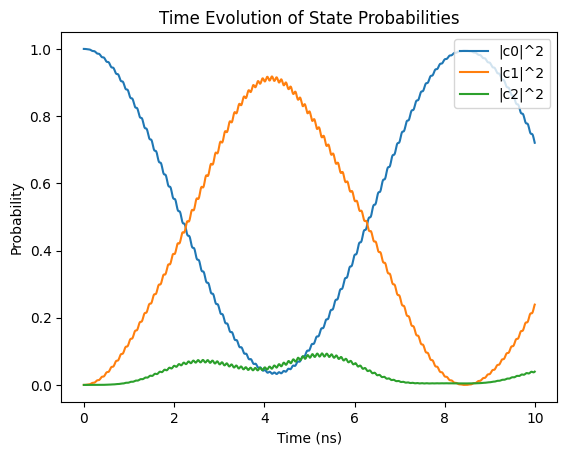

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import linalg as sla
from scipy import sparse as sp
from myfunctions import rk4solve
from part2 import H_number, H_time

def H_number(N, Ec, Ej):
    M=len(N)-1 # since the upper and lower diagonal has 1 less element than the diagonal
    K= 4*Ec*np.diag(N**2,0)
    V= -Ej/2 * (np.diag(np.ones(M),1)+np.diag(np.ones(M),-1))
    H=sp.csr_matrix(K+V)
    return(H) 
def H_drive(t,omega, w,A):
    return(omega*np.sin(w*t)*A) 

def H_time(t,H0,A,omega,w): #the time dependent hamiltonian
    return(H0+H_drive(t,omega,w,A))

def f(t,c): #the function for the ODE solver
    return(-1j*H_time(t,H_0,A,omega,w)@c)
if __name__ == "__main__": # so that the code below only runs when this file is run directly and not when it is imported into another file.
    # Now have a ODE where dy/dt = f(t,y) which I can solve using RK4 from computer lab.

    #create the hamilton and the initial density matrix
    ##
    E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz
    E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
    N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
    t1, t2= 200, 150 # the relaxation and dephasing times in ns
    gamma=np.array([1/t1,2 * (1/t2 - 1 / (2*t1))]) # the dissipation rates for the two levels
    T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
    T2 = np.diag([0,1,2]) # adagger a 
    T = np.array([T1,T2]) # the array of the two operators
    rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]],dtype=complex) # the initial density matrix

    H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
    E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
    H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
    w = E[1]-E[0] # the energy gap between the ground state and the first excited state
    A= U.T @ np.diag(N) @ U #the coupling term between the different states
    t_grid = np.arange(0, T_g + dT_g, dT_g) #grid of time points for the integration from 0 to T_g with step size dT_g
    area = np.trapezoid(gaussian(t_grid, mu, sigma), t_grid) #integrate the gaussian function over the time grid to get the area under the curve
    omega = np.pi / (abs(A[0, 1]) * area)
    ### Solve the Lindblad equation using RK4
    c0=np.array([1,0,0]) # the initial condition
    t,C = rk4solve(f, c0, 0, 0.005, 10)

    plt.plot(t, np.abs(C[:, 0])**2, label='|c0|^2')
    plt.plot(t, np.abs(C[:, 1])**2, label='|c1|^2')
    plt.plot(t, np.abs(C[:, 2])**2, label='|c2|^2')
    plt.xlabel('Time (ns)')
    plt.ylabel('Probability')
    plt.title('Time Evolution of State Probabilities')
    plt.legend(loc='upper right')
    plt.show()